# Project 3 (Due November 6): Clustering and Anomaly Detection


This project studies two different kinds of irregularities in financial data: **isolated recording errors** and a **contiguous interval of unusual joint statistical behavior**. You will use DBSCAN for the former and window-based covariance representations with PCA, K-means, and hierarchical clustering for the latter.

Use only `polluteddata.csv`. You may use NumPy, pandas, SciPy, Matplotlib, and scikit-learn. Fix random seeds where appropriate and state your main modeling choices.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

SEED = 4500


## Data

The file contains **1,709 half-hour observations of one asset**, with no header. Using zero-based column numbers, column 0 is the half-hour index $t$, and column $k+1$ contains

$$
x_{t,k}=p(t,k)-p(t,0),\qquad k=0,\ldots,29,
$$

where $p(t,k)$ is the recorded price at minute $k$ within half-hour $t$. These are price differences, **not** percentage returns. Each row therefore includes the half-hour index and 30 intraperiod measurements (the minute-0 price change is zero).

The data contain **exactly six isolated recording errors**, at unknown observations and minutes. Separately, during an unknown **contiguous interval $[t_1,t_2]$**, the data exhibit a significant change in their **joint statistical behavior**, particularly covariance structure. Your goals are to identify the six isolated errors and estimate the anomalous interval.



In [4]:
data = pd.read_csv('polluteddata.csv', header=None)
print('Data shape:', data.shape)
print(data.head(3))


Data shape: (1709, 31)
    0    1     2     3      4     5      6      7      8      9   ...     21  \
0  0.0  0.0 -3.00 -8.26 -10.55 -8.56 -18.08 -12.67 -14.29 -16.08  ... -27.58   
1  1.0  0.0  0.12 -0.41  -2.56  0.15  -1.65  -5.14  -5.09  -8.06  ...  -6.65   
2  2.0  0.0 -2.80 -3.46  -5.80 -3.86  -2.60  -5.30  -4.81  -3.30  ... -12.74   

      22     23     24     25     26     27     28     29     30  
0 -31.51 -27.53 -25.24 -25.32 -24.44 -28.04 -30.94 -29.57 -27.56  
1  -5.43  -6.13  -3.42  -4.48  -4.85  -4.47  -4.68  -2.10  -0.28  
2 -13.02 -15.99 -14.15 -14.92 -16.80 -16.88 -19.53 -25.30 -19.60  

[3 rows x 31 columns]


# Task 1: Data exploration and preprocessing

Inspect the data, check its basic structure and quality, and provide a simple exploratory visualization. Prepare suitable feature representations for the subsequent tasks.

In [5]:
# Task 1: your data exploration and preprocessing


print("Shape:", data.shape)
print("\nData types:")
print(data.dtypes.value_counts())


print("\nMissing values:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Infinite values:", np.isinf(data.to_numpy()).sum())

print("\nSummary statistics:")
display(data.iloc[:, 1:].describe())

Shape: (1709, 31)

Data types:
float64    31
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0
Infinite values: 0

Summary statistics:


,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
count,1709.0,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,...,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000
mean,0.0,0.094744,0.006594,0.066914,0.294528,0.224361,0.313219,-0.004143,0.169033,0.091920,...,-0.273401,0.209558,0.186624,0.278519,0.278602,-0.131089,0.171991,-0.135022,-0.105291,0.291442
std,0.0,3.247338,6.197354,6.034463,5.546020,6.385154,6.846385,10.741715,7.988759,8.606869,...,17.102589,10.611540,10.812969,11.127263,11.527265,14.472260,12.298652,14.325939,15.023754,13.195456
min,0.0,-15.650000,-56.960000,-66.380000,-38.380000,-46.020000,-46.740000,-64.360000,-47.880000,-51.720000,...,-96.827911,-68.190000,-72.410000,-78.670000,-70.880000,-75.600000,-74.070000,-71.777607,-78.234077,-64.820000
25%,0.0,-1.100000,-1.779856,-2.260000,-2.230000,-2.750000,-2.990000,-3.540000,-3.740000,-4.160000,...,-6.090000,-5.480000,-5.420000,-5.420364,-5.720000,-6.610000,-5.980000,-6.950000,-7.220000,-6.600000
50%,0.0,-0.010000,0.070000,0.040000,0.060000,0.080000,0.050000,0.100000,0.040000,0.060000,...,-0.200000,-0.130000,-0.340000,-0.080000,-0.140000,-0.230000,-0.230000,-0.490000,-0.310000,-0.070000
75%,0.0,1.188527,1.860000,2.290000,2.392062,2.890000,3.200000,3.520000,3.460000,3.520000,...,5.880000,5.300000,5.270000,5.370000,5.530000,5.770000,5.630000,5.980000,6.290000,6.540000
max,0.0,60.380000,67.930000,64.060000,68.040000,76.880000,83.300000,78.830000,84.440000,79.840000,...,87.569365,88.050000,88.300000,92.190000,96.050000,100.080000,101.070000,94.510000,98.690000,101.570000


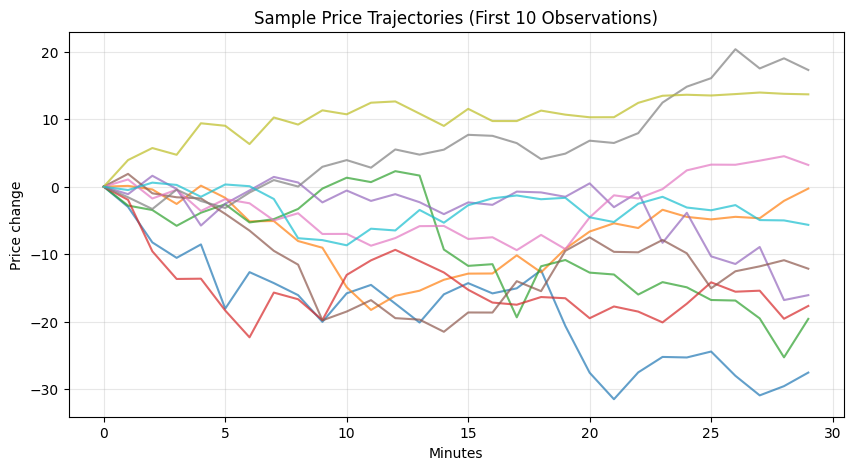

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.plot(range(30), data.iloc[i, 1:], alpha=0.7)

plt.xlabel("Minutes")
plt.ylabel("Price change")
plt.title("Sample Price Trajectories (First 10 Observations)")
plt.grid(alpha=0.3)
plt.show()


From the above graph, we can see that the sampled price trajectorie all begin at 0 at time 0 and diverge from there. The spread in behavior increases over time, and further analysis is required to understand this.

In [7]:
time_idx = data.iloc[:, 0].to_numpy()
X = data.iloc[:, 1:].to_numpy()

# minute-to-minute price changes
X_diff = np.diff(X, axis=1)

print("Original features:", X.shape)
print("Minute-to-minute changes:", X_diff.shape)

Original features: (1709, 30)
Minute-to-minute changes: (1709, 29)


In [8]:
from sklearn.preprocessing import StandardScaler

X_features = X[:, 1:]

# standardize feature representations
X_scaled = StandardScaler().fit_transform(X_features)
X_diff_scaled = StandardScaler().fit_transform(X_diff)

print("Scaled price changes:", X_scaled.shape)
print("Scaled minute-to-minute changes:", X_diff_scaled.shape)


Scaled price changes: (1709, 29)
Scaled minute-to-minute changes: (1709, 29)


The dataset has 1709 observations and 30 price measurements per observation. There are no missing or duplicate rows. In the graph, we saw that the price may fluctuate either up or down, and the spread generally increased with time over the 30 minute dataset given. For preprocessing, minute 0 was removed and time indices were separated from price measurements. We also calculated the minute by minute changes of the price so that we can see more specific changes rather than just the cumulative movement. We also created a standardized version of both feature representations (for distance-based clustering). The original dataset was retained and no observations were removed.

# Task 2: DBSCAN — isolated recording errors

Apply DBSCAN to identify the **six isolated recording errors**.

1. Choose a representation of each half-hour observation and an appropriate distance metric. Briefly justify your choices.
2. Select `eps` and `min_samples`, using a neighborhood-distance diagnostic or another systematic parameter-selection approach. You **may use the known number of recording errors (six)** to guide your selection, but should not assume that six noise labels guarantee six correct detections.
3. Report the candidate error half-hour indices, the number of DBSCAN clusters, and the noise count.
4. Examine whether your results remain reasonably stable for nearby parameter choices, and discuss possible false positives or missed errors.

Do not assume that DBSCAN noise observations must coincide with the contiguous anomalous interval.

### 1. Features and distance

Using `X_diff` from Task 1, we measure each interior minute's deviation from its two neighbors

$$r_{t,k}=x_{t,k}-\frac{x_{t,k-1}+x_{t,k+1}}{2},\qquad k=1,\ldots,28$$

This highlights isolated spikes and removes locally linear trends
We use Euclidean distance without standardizing because all 28 features share the same price units and minute spacing, giving equal weight to equal-sized deviations
All rows are retained, and time is excluded from the features
We start with the class example's `min_samples = 5`

In [9]:
#Measure local price deviations
X_dbscan = -0.5 * np.diff(X_diff, axis=1)
#Use Euclidean distance
metric = "euclidean"
#Set the minimum count including self
min_samples = 5
#Set the radius for inspection
eps = 45
#Show the feature dimensions
print("DBSCAN features:", X_dbscan.shape)

DBSCAN features: (1709, 28)


### 2. Choose the radius

We request five neighbors including the observation itself, giving the distance to the fourth other neighbor
The plots show all distances and the largest 25
A point above `eps` is not core, but could still be border rather than noise

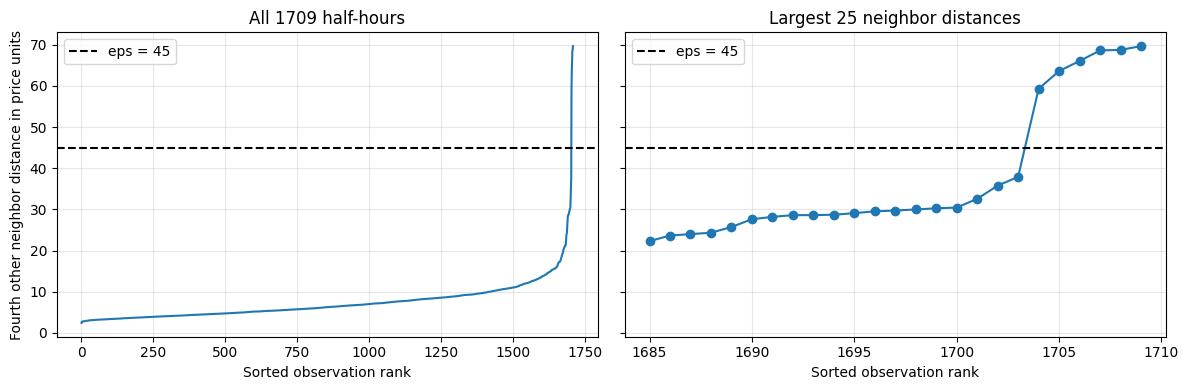

,Half-hour,Distance
260,260,35.790
1644,1644,37.919
90,90,59.300
351,351,63.633
1576,1576,66.065
1334,1334,68.628
1081,1081,68.767
658,658,69.670


In [10]:
#create neighbor model
neighbors = NearestNeighbors(n_neighbors=min_samples, metric=metric)
#fit neighbor model
neighbors.fit(X_dbscan)
#find neighbors including each point
distances, neighbor_indices = neighbors.kneighbors(X_dbscan)
#keep final neighbor distance
k_distances = distances[:, -1]
#sort distances
sorted_distances = np.sort(k_distances)
#create sorted ranks
ranks = np.arange(1, len(sorted_distances) + 1)
#create diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
#plot all observations
axes[0].plot(ranks, sorted_distances, color="tab:blue")
axes[0].set_title("All 1709 half-hours")
#largest distances
axes[1].plot(ranks[-25:], sorted_distances[-25:], marker="o", color="tab:blue")
#enlarged plot
axes[1].set_title("Largest 25 neighbor distances")
#format both panels
for ax in axes:
    #mark selected radius
    ax.axhline(eps, color="black", linestyle="--", label=f"eps = {eps}")
    #observation ranks
    ax.set_xlabel("Sorted observation rank")
    ax.grid(alpha=0.3)
    #radius label
    ax.legend()
#distance scale
axes[0].set_ylabel("Fourth other neighbor distance in price units")
#fit plot spacing
plt.tight_layout()
#diagnostic plots
plt.show()
#collect neighbor distances
neighbor_summary = pd.DataFrame({"Half-hour": time_idx.astype(int), "Distance": k_distances})
#show largest eight distances
display(neighbor_summary.sort_values("Distance").tail(8).round(3))

The gap from **37.919 to 59.300** separates six observations from the rest
We choose **eps = 45** inside this gap, then inspect the candidates and test nearby settings rather than relying only on the known error count

### 3. Fit DBSCAN

In [11]:
#create DBSCAN model
dbscan = DBSCAN(eps=eps, min_samples=min_samples, metric=metric)
#fit and collect labels
dbscan_labels = dbscan.fit_predict(X_dbscan)
#identify noise observations
noise_mask = dbscan_labels == -1
#count clusters without noise
n_clusters = len(set(dbscan_labels) - {-1})
#count noise observations
n_noise = int(np.sum(noise_mask))
#keep candidate row positions
error_rows = np.flatnonzero(noise_mask)
#recover original half-hour indices
error_indices = time_idx[noise_mask].astype(int)
#number of clusters
print("Number of DBSCAN clusters:", n_clusters)
#number of noise points
print("Number of noise observations:", n_noise)
#candidate indices
print("Candidate error half-hours:", error_indices.tolist())

Number of DBSCAN clusters: 1
Number of noise observations: 6
Candidate error half-hours: [90, 351, 658, 1081, 1334, 1576]


### 4. Inspect the candidates

For each flagged half-hour, the table and plots identify the minute with the largest absolute local deviation

In [12]:
#find each suspected minute
error_minutes = np.argmax(np.abs(X_dbscan[error_rows]), axis=1) + 1
#start candidate table
error_summary = pd.DataFrame({"Half-hour": error_indices, "Minute": error_minutes})
#record preceding measurements
error_summary["Previous"] = X[error_rows, error_minutes - 1]
#record suspected measurements
error_summary["Recorded"] = X[error_rows, error_minutes]
#record following measurements
error_summary["Next"] = X[error_rows, error_minutes + 1]
#record local deviations
error_summary["Local deviation"] = X_dbscan[error_rows, error_minutes - 1]
#show candidate evidence
display(error_summary.round(3))

,Half-hour,Minute,Previous,Recorded,Next,Local deviation
0,90,1,0.00,60.38,1.70,59.530
1,351,2,-0.46,-56.96,4.47,-58.965
2,658,4,1.11,61.26,-0.63,61.020
3,1081,3,-2.15,-66.38,-5.65,-62.480
4,1334,5,0.06,61.23,0.48,60.960
5,1576,7,-4.22,-64.36,-3.97,-60.265


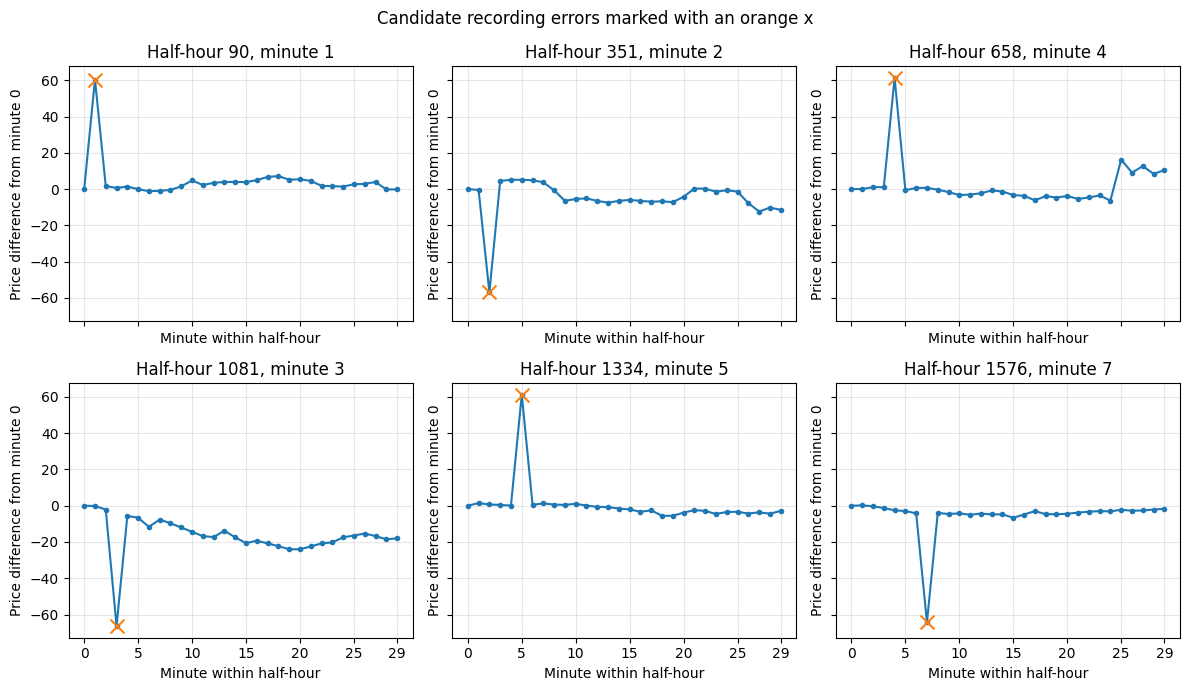

In [13]:
#create shared scales for candidates
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
#plot each candidate trajectory
for ax, row, minute in zip(axes.ravel(), error_rows, error_minutes):
    ax.plot(np.arange(30), X[row], marker="o", markersize=3, color="tab:blue")
    #highlight suspected error
    ax.scatter(minute, X[row, minute], marker="x", s=100, color="tab:orange", zorder=3)
    ax.set_title(f"Half-hour {int(time_idx[row])}, minute {minute}")
    ax.set_xlabel("Minute within half-hour")
    ax.set_ylabel("Price difference from minute 0")
    ax.set_xticks([0, 5, 10, 15, 20, 25, 29])
    ax.grid(alpha=0.3)
fig.suptitle("Candidate recording errors marked with an orange x")
plt.tight_layout()
plt.show()

DBSCAN finds **one cluster of 1,703 observations and six noise points**: **90, 351, 658, 1081, 1334, and 1576**
Each shows a spike followed by a reversal, supporting the recording-error interpretation
Their absolute local deviations range from **58.965 to 62.480 price units**

### 5. Check stability

We vary both parameters and compare the actual noise indices, not just the count

In [14]:
#choose radii around selected value
eps_values = [35, 40, 45, 50, 55]
#use class neighborhood examples
min_samples_values = [3, 5, 12]
#prepare comparison records
parameter_results = []
#vary neighborhood size
for min_points in min_samples_values:
    #vary neighborhood radius
    for radius in eps_values:
        #create comparison model
        model = DBSCAN(eps=radius, min_samples=min_points, metric=metric)
        #fit same features
        labels = model.fit_predict(X_dbscan)
        #identify comparison noise
        current_noise = labels == -1
        #recover flagged half-hours
        current_indices = time_idx[current_noise].astype(int).tolist()
        #record parameter choices
        result = {"eps": radius, "min_samples": min_points}
        #record cluster count
        result["Clusters"] = len(set(labels) - {-1})
        #record noise count
        result["Noise"] = int(np.sum(current_noise))
        #check full noise membership
        result["Same candidates"] = np.array_equal(current_noise, noise_mask)
        #record actual candidate indices
        result["Candidate half-hours"] = current_indices
        #save comparison
        parameter_results.append(result)
#build parameter table
sensitivity = pd.DataFrame(parameter_results)
display(sensitivity)

,eps,min_samples,Clusters,Noise,Same candidates,Candidate half-hours
0,35,3,1,7,False,"[90, 351, 658, 1081, 1334, 1576, 1644]"
1,40,3,1,6,True,"[90, 351, 658, 1081, 1334, 1576]"
2,45,3,1,6,True,"[90, 351, 658, 1081, 1334, 1576]"
3,50,3,1,6,True,"[90, 351, 658, 1081, 1334, 1576]"
4,55,3,1,4,False,"[658, 1081, 1334, 1576]"
5,35,5,1,7,False,"[90, 351, 658, 1081, 1334, 1576, 1644]"
6,40,5,1,6,True,"[90, 351, 658, 1081, 1334, 1576]"
7,45,5,1,6,True,"[90, 351, 658, 1081, 1334, 1576]"
8,50,5,1,6,True,"[90, 351, 658, 1081, 1334, 1576]"
9,55,5,1,4,False,"[658, 1081, 1334, 1576]"


The same six candidates appear in all **nine combinations** of `eps = 40, 45, 50` and `min_samples = 3, 5, 12`
At `eps = 35`, half-hour **1644** is also flagged; at `eps = 55`, **90 and 351** join the cluster
This shows stability nearby and possible extra or missed detections farther away

### Limitations

Genuine price reversals can resemble errors, and smaller, endpoint, or consecutive errors may be missed
Results depend on the features, scaling, and parameters; dense unusual groups may remain clustered
Without clean reference data, these remain candidates
Task 2 does not identify the contiguous covariance-anomaly interval
Original data are unchanged, and `error_indices` and `error_summary` are available for later tasks

### References

Week 7 DBSCAN notebook, Sections 1 and 4; Week 7 Anomaly Detection slides 4, 6, 14–16, and 19; Week 6 Clustering I slide 11
Local-deviation features are our project-specific choice

A *window* in Tasks 3–4 consists of consecutive **half-hour observations (rows)**, not consecutive minutes within a half-hour. Cluster labels are arbitrary; a cluster or noise label alone does not prove that an observation is anomalous.

# Task 3: Window-based covariance analysis, PCA, and K-means

The main objective is to identify the **contiguous interval** with unusual joint statistical behavior. Instead of clustering individual half-hours, study how the data's covariance structure evolves across **windows of consecutive half-hours**.

1. Construct an informative window-level representation of covariance behavior. Choose and briefly motivate the windowing and feature-design choices.
2. Use **PCA and K-means** to investigate patterns across windows. Select reasonable settings and interpret the resulting groups.
3. Provide visualizations that connect the window-level results back to time and indicate any unusual statistical regime.
4. Report an estimated interval $[\hat t_1,\hat t_2]$ and explain how you infer its boundaries from your results. Discuss any important uncertainty introduced by the window construction.

You have flexibility in feature construction and parameter selection; justify your design rather than following a prescribed recipe.

### Discussion 1:
It is unclear whether using the orignal data of cumulative price changes in the half hour window or the difference version that capture the minute-level change would yield a better performance in coveriance behavior analysis.

**1)** The original data record a cumulative time-series behavior, any two time points are naturally correlated, the covariance matrix have more significance in off-diagonal values, the transition in covariance structure across windows could be reflected by off-diagonal values, so the variance features would not be the sole driver, there is likely more PCs having large explanatory power to be considered for K-means.

**2)** The differenced data smoothed out some joint behaviour of prices, the off-diagonal values are usually small, yielding a nearly diagonal matrix, cross-window value change of off-diagonal values are largely random noise. However, the minute level change could be more obvious, and likely PC1 could account for more variability.

The primary focus would be still on **the original data**, since large PC1 explainabiltiy is not necessarily a good thing, dominance of variance and PC1 would create very limited information for K-means, with only one dimension of feature for clustering, the result may not be robust across changes in parameter

The size of rolling window is initially set at $h=50$, with rolling stepsize of $d=1$ for more accurate approximation,each window therefore has dimension $h\times 29$, the covariance matrix is computed within each normal (without standardization of price changes since changing of absolute variance itself could be indicator of unusual joint statistical behavior. Across the each window the $29\times 29$ covariance matrix is taken upper right triangle and flattened into a $1\times 435$ feature matrix. The whole data set is therefore of dimension $1660\times 435$. The features capture the minute level covariance changes within each window.

Two sets of standardization is conducted, not to completely wipe out the variance change across window, but to reduce its influence in PCA (since diagonal values of the covariance matrix is naturally larger in  magnitude, we need to avoid PCA being driven by mostly their variation), so cross window standardizaiton for each one out of the 435 features is conducted, to make them comparable with each other. The PC-score is also standardized across the windows, to aviod PC1's dominance in clustering given its large variance.

### Discussion 2:
For high dimension feature space, retaining PCs involves tradeoff between explainability of variability and too much noise introduced. But given this "time series data" on the same asset, multicollinearity is expected, the first PC already accounts for 66% of variation, and first 2 PC explain 90%.

The initial number of PC retained is set at $p=2$, to at least have more dimensions to consider when performing K-means. The Elbow plot is displayed, the turning point is around $k=3$,so the initial choice of number of clusters is set at $k=2$ (distinct ususual vs unusual class) with $k=3,4,5$ checked subsequently for robustness of results.

Large number of clusters is proven to be very conservative, creating unnecessary seperations, but there is still a consecutive interval of window $731-928$ segmented from the rest of the group. K-means clustering is conducted on the scores matrix $1660\times p$.

In [15]:
# Task 3: your window features, PCA, K-means, and interval estimate
# Definition of parameters
h=50 # Window size (rows)
d=1 # rolling stepsize (row)
# p: number of features retained
p=2
# k in K-means to be selected with Elbow method
# Loading data
print(data.shape)
data_copy=data.iloc[:,1:]
data_new=np.diff(data_copy,axis=1)
df=pd.DataFrame(data.iloc[:,2:],index=data[0])
print(df.head())

(1709, 31)
       2     3      4      5      6      7      8      9      10     11  ...  \
0                                                                        ...   
0.0 -3.00 -8.26 -10.55  -8.56 -18.08 -12.67 -14.29 -16.08 -20.04 -15.81  ...   
1.0  0.12 -0.41  -2.56   0.15  -1.65  -5.14  -5.09  -8.06  -9.05 -14.90  ...   
2.0 -2.80 -3.46  -5.80  -3.86  -2.60  -5.30  -4.81  -3.30  -0.28   1.33  ...   
3.0 -1.95 -9.58 -13.68 -13.64 -18.36 -22.33 -15.70 -16.69 -19.78 -13.08  ...   
4.0 -1.11  1.62  -0.34  -5.76  -2.53  -0.56   1.45   0.62  -2.33  -0.57  ...   

        21     22     23     24     25     26     27     28     29     30  
0                                                                          
0.0 -27.58 -31.51 -27.53 -25.24 -25.32 -24.44 -28.04 -30.94 -29.57 -27.56  
1.0  -6.65  -5.43  -6.13  -3.42  -4.48  -4.85  -4.47  -4.68  -2.10  -0.28  
2.0 -12.74 -13.02 -15.99 -14.15 -14.92 -16.80 -16.88 -19.53 -25.30 -19.60  
3.0 -19.50 -17.76 -18.52 -20.12 -17.35 -14.18 -1

(1660, 50, 29)


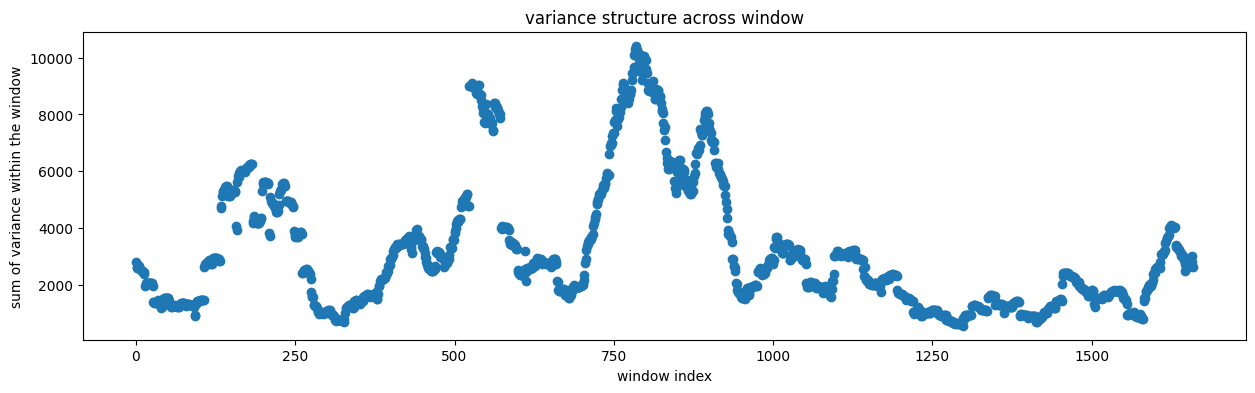

(1660, 435)
PC1 top features: [257 218 275 238 197]
PC2 top features: [170 172 180 177 235]
257 of PC1 top loadings is off-diagonal
218 of PC1 top loadings is off-diagonal
275 of PC1 top loadings is off-diagonal
238 of PC1 top loadings is off-diagonal
197 of PC1 top loadings is off-diagonal
170 of PC2 top loadings is off-diagonal
172 of PC2 top loadings is off-diagonal
180 of PC2 top loadings is off-diagonal
177 of PC2 top loadings is off-diagonal
235 of PC2 top loadings is off-diagonal
Explained variation at p=2 is 0.9032992434863317


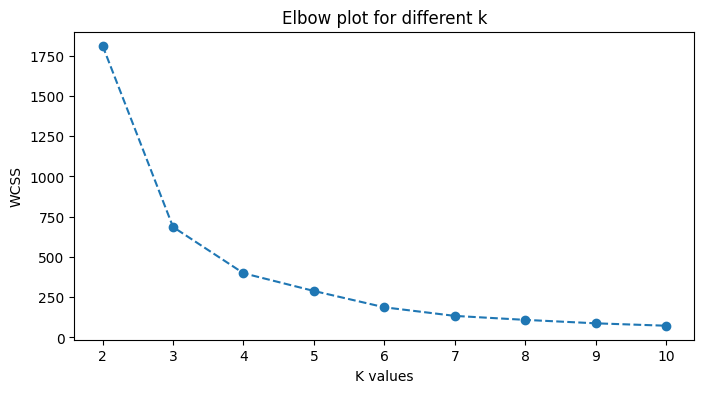

In [16]:
# Below is the implementation with the flattened upper right triangle covariance matrix from each window as features
# function for rolling window construction, computing window level features (29x29->1x435)
# compelling window level features across all windows (# of total windows x 435)
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

def window_cov(df,h,d,m):# m as the number of subintervals in the row, eg minute-level:m=30, the later analysis of 5min level data m=6
    # sliding window view (1660,29,50)
    windows=sliding_window_view(df,window_shape=h,axis=0)
    # slicing for stepsize=d
    windows=windows[::d]
    # transpose to get (1660,50,29)
    windows=windows.transpose(0,2,1)
    print(windows.shape)
    # Covariance matrix across all windows (1660,29,29)
    centered=windows-np.mean(windows,axis=1,keepdims=True)
    cov_matrices=np.matmul(centered.transpose(0,2,1),centered)/(h-1)
    # plot the trace to check the variance structure
    trace_w = np.trace(cov_matrices, axis1=1, axis2=2)
    plt.figure(figsize=(15, 4))
    plt.scatter(np.arange(0,windows.shape[0],1),trace_w)
    plt.xlabel('window index')
    plt.ylabel('sum of variance within the window')
    plt.title('variance structure across window')
    plt.show()
    # Taking the upper left triangle and flatten (1660,435)
    features=cov_matrices[:,np.triu_indices(m-1)[0],np.triu_indices(m-1)[1]]
    # Standardize each feature across window
    scaler=StandardScaler()
    features=scaler.fit_transform(features)
    print(features.shape)
    return features

# function of PCA across the covariance matrix (435x435), checking for features retains, obtaining score (# number of windows x p)
def PCA_km(features):
    pca=PCA(n_components=p,random_state=SEED)
    score=pca.fit_transform(features)
    loadings = pca.components_  # (p, 435)
    # Check the top five largest PC loadings'index in the flatten feature space
    pc1_tpload=np.argsort(np.abs(loadings[0]))[-5:]
    pc2_tpload=np.argsort(np.abs(loadings[1]))[-5:]
    print("PC1 top features:", pc1_tpload)
    print("PC2 top features:", pc2_tpload)
    # Check whehter they are off diagonal in the original cov matrix
    rows,cols=np.triu_indices(29)
    for idx in pc1_tpload:
        result=f'{idx} of PC1 top loadings is off-diagonal' if rows[idx]!=cols[idx] else f'{idx} of PC1 top loadings is on the diagonal'
        print(result)
    for idx in pc2_tpload:
        result=f'{idx} of PC2 top loadings is off-diagonal' if rows[idx]!=cols[idx] else f'{idx} of PC2 top loadings is on the diagonal'
        print(result)
    # standardize the score across the p PCs
    scaler=StandardScaler()
    score=scaler.fit_transform(score[:,:p])
    print(f'Explained variation at p={p} is {sum(pca.explained_variance_ratio_)}')
    return score

# function of K-means across score matrix, under a given list of k
def k_means(score,lst_k):
    lst_inertia=[]
    for k in lst_k:
        kmeans=KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=SEED)
        kmeans.fit(score)
        lst_inertia.append(kmeans.inertia_)
    plt.figure(figsize=(8,4))
    plt.plot(lst_k,lst_inertia,marker='o',linestyle='--')
    plt.title('Elbow plot for different k')
    plt.xlabel('K values')
    plt.ylabel('WCSS')
    plt.show()
    return

# Main function of defining list of K variables, calling K-means function to check WCSS and select a k for final evaluation
lst_k=np.arange(2,11,1)
features=window_cov(df,h,d,30)
score=PCA_km(features)
k_means(score,lst_k)

In [17]:
k=2
kmeans=KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=SEED)
labels=kmeans.fit_predict(score)
features_groups=pd.DataFrame({
    'Window idx':np.arange(0,features.shape[0],1),
    'Cluster':labels+1})
for i,group in features_groups.groupby('Cluster'):
    print(f'Cluster {i} ({len(group)} intervals):{group.index}')

Cluster 1 (1462 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1462)
Cluster 2 (198 intervals):Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740,
       ...
       919, 920, 921, 922, 923, 924, 925, 926, 927, 928],
      dtype='int64', length=198)


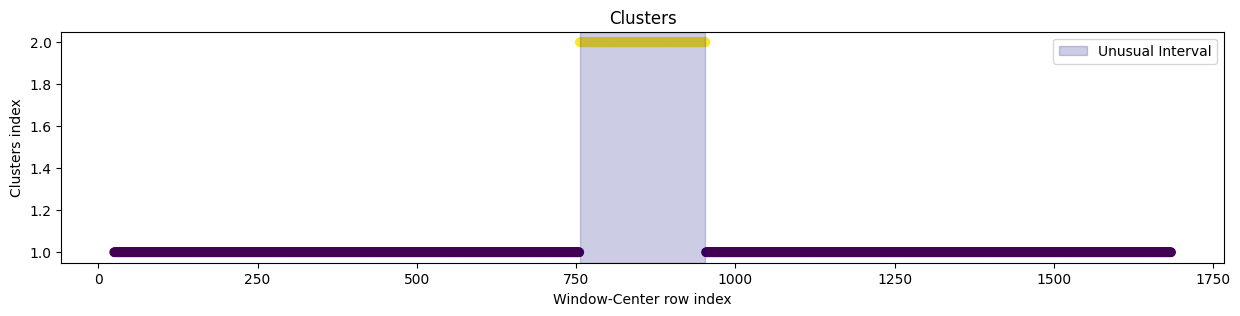

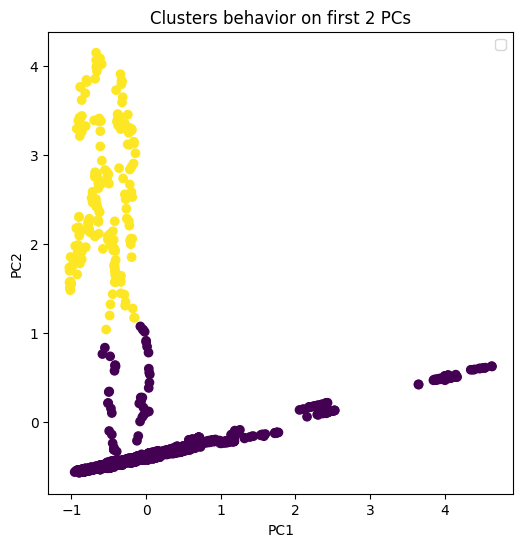

In [18]:
# Function for visualization linking back to time interval
def visualization(features_groups,h,d,start,end):#start and end of the abnormal interval
    # clusters displayed on the original timeline,with each window indexed with center-row (1709)
    orig_idx=np.arange(features_groups.shape[0])+h//2
    plt.figure(figsize=(15,3))
    plt.scatter(orig_idx,features_groups['Cluster'],c=features_groups['Cluster'])
    plt.axvspan(start+h//2,end+h//2,color='navy',alpha=0.2,label='Unusual Interval')
    plt.title('Clusters')
    plt.xlabel('Window-Center row index')
    plt.ylabel('Clusters index')
    plt.legend()
    plt.show()
    # Clustering on PC1 and PC2
    plt.figure(figsize=(6,6))
    plt.scatter(score[:,0],score[:,1],c=features_groups['Cluster'])
    #plt.scatter(score[:,0],np.ones(len(score[:,0])),c=features_groups['Cluster'])
    plt.title('Clusters behavior on first 2 PCs')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.legend()
    plt.show()

visualization(features_groups,h,d,731,928)

### Discussion 3:

Creating the plots above,it is clear that a period of consecutive windows is segmented to a seperate cluster due to different statistical behavior. the window index is translated back to the center row of the window, so the corresponding **center row** of the unusual interval is around $756-952$ as demonstrated above, which means under $h=50$, the unusual window is spanning across the $731th$ to $977th$ half-hour row, however there is error in approximation due to window size, it is hard to tell which specific rows marks the transition of two 'regimes.

Studying the different behavior of clusters on the first 2 PCs, the unusual interval has a larger absolute value for PC2. The usual period has PC2 smaller in absolute value term, variation concentrated across PC1, displaying rather consistent changes in value. PC1 could be intepreted as the common structural flucuations in volatility due to regular trend flows, while PC2 is more of the sudden change of covariance pattern that concentrated in a specific period.

From studying in the largest loadings index of PC1 and PC2, they are all off-diagonal covariance, therefore, the driver of unusual regime shift is primarily the change in covariance of two different minutes across windows, instead of sudden shift in volatility of particular minute.


------------------Results with k=3,window size =30------------------------
Cluster 1 (1347 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1347)
Cluster 2 (116 intervals):Index([133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       ...
       563, 564, 565, 566, 567, 568, 569, 570, 571, 572],
      dtype='int64', length=116)
Cluster 3 (197 intervals):Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740,
       ...
       918, 919, 920, 921, 922, 923, 924, 925, 926, 927],
      dtype='int64', length=197)

------------------Results with k=3,window size =100------------------------
Cluster 1 (1347 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1347)
Cluster 2 (116 intervals):Index([133, 134, 135, 136, 137, 138, 

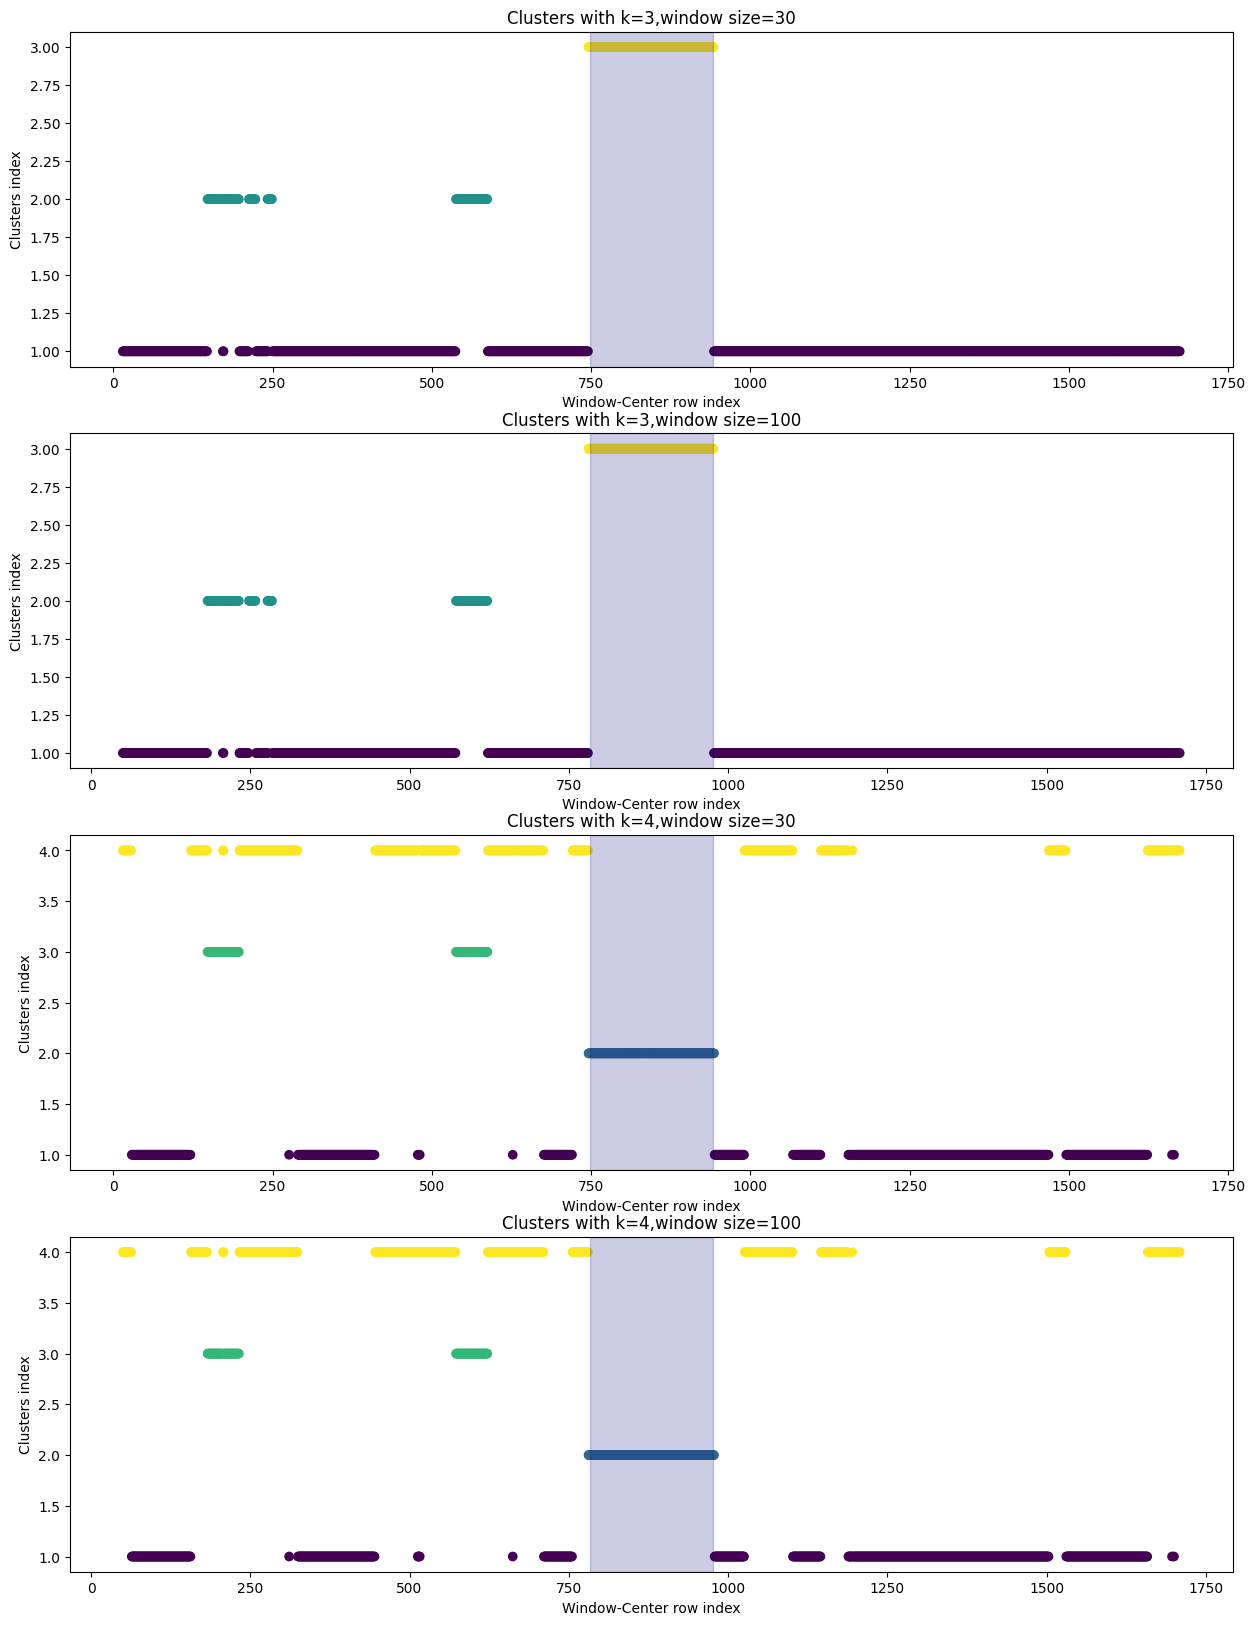

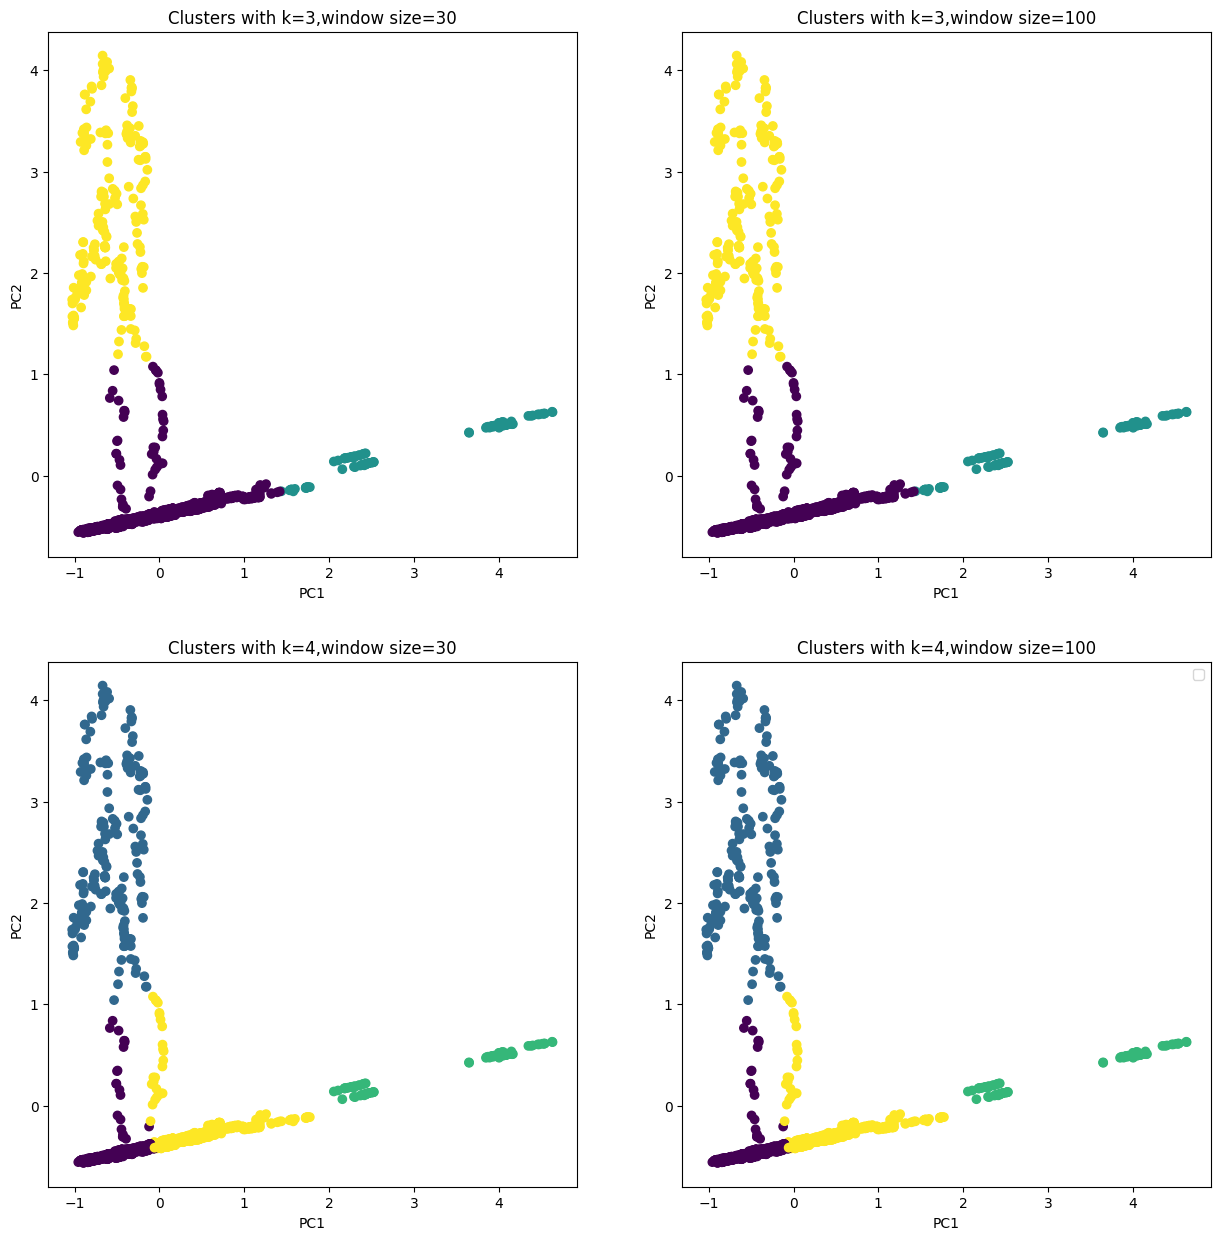

In [19]:
# Some robustness check across different values of h and k
from matplotlib.pyplot import subplots
fig,axes=plt.subplots(4,1,figsize=(15,20))
axes=axes.flatten()
axes_pc=plt.subplots(2,2,figsize=(15,15))[1]
axes_pc=axes_pc.flatten()
idx=0
for k in range(3,5):
    for h in [30,100]:
        kmeans=KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=10,
                    max_iter=300,
                    tol=1e-4,
                    random_state=SEED)
        labels=kmeans.fit_predict(score)
        features_groups=pd.DataFrame({
            'Window idx':np.arange(0,features.shape[0],1),
            'Cluster':labels+1})
        print(f'\n------------------Results with k={k},window size ={h}------------------------')
        for i,group in features_groups.groupby('Cluster'):
            print(f'Cluster {i} ({len(group)} intervals):{group.index}')
        # plot
        orig_idx=np.arange(features_groups.shape[0])+h//2
        axes[idx].scatter(orig_idx,features_groups['Cluster'],c=features_groups['Cluster'])
        axes[idx].axvspan(733+h//2,927+h//2,color='navy',alpha=0.2,label='Unusual Interval')
        axes[idx].set_title(f'Clusters with k={k},window size={h}')
        axes[idx].set_xlabel('Window-Center row index')
        axes[idx].set_ylabel('Clusters index')
        axes_pc[idx].scatter(score[:,0],score[:,1],c=features_groups['Cluster'])
        axes_pc[idx].set_title(f'Clusters with k={k},window size={h}')
        axes_pc[idx].set_xlabel('PC1')
        axes_pc[idx].set_ylabel('PC2')
        idx+=1
plt.legend()
plt.show()

### Discussion 4:
The main unsuual regime is around the center rows of the indexed window $731$ and $928$, these window indices are equivalently the index of the first row in corresponding window. It is worth noting that changing of window size alone across $30$, $50$, and $100$ does not change the unusual clusters' window index, while changing k some times have window $928$ clustered as 'usual', which is intuitive since at the boundary of unusual regime, the mixuture of rows constructing the window will overall the result is robust across different parameter values.

Under $h=50$, the anomalous regime took place from around $731th$ to $976th$ half hour which is the from the first row of window 733 to the last row: $928+50-1=977$ of window 928, with the core regime shift centered aorund $758$ to $952$ (center rows of the two windows).

Uncertainty occurs due to the blurred effects around the boundaries.Because each window contains 50 consecutive half-hour observations, a window is labeled "anomalous" as long as a significant portion of its 50 rows included the true anomaly data, and we do not know when its 'contamination' effect on a particular window starts to be significant enough to be captured.

## A trial with differenced data to check robustness of results

(1660, 50, 29)


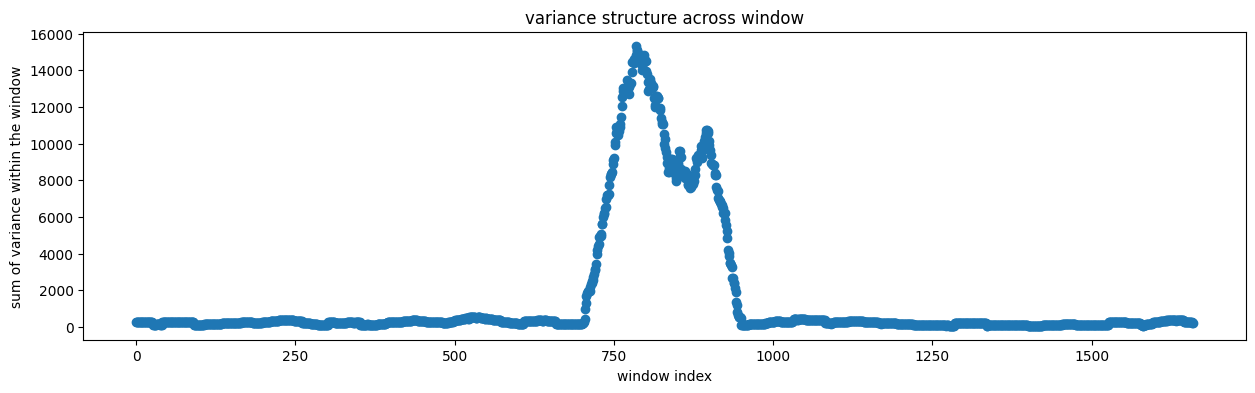

(1660, 435)
PC1 top features: [325 395 320 321 394]
PC2 top features: [ 15 206 204   0 245]
325 of PC1 top loadings is off-diagonal
395 of PC1 top loadings is off-diagonal
320 of PC1 top loadings is off-diagonal
321 of PC1 top loadings is off-diagonal
394 of PC1 top loadings is off-diagonal
15 of PC2 top loadings is off-diagonal
206 of PC2 top loadings is off-diagonal
204 of PC2 top loadings is on the diagonal
0 of PC2 top loadings is on the diagonal
245 of PC2 top loadings is on the diagonal
Explained variation at p=2 is 0.9461664009807617


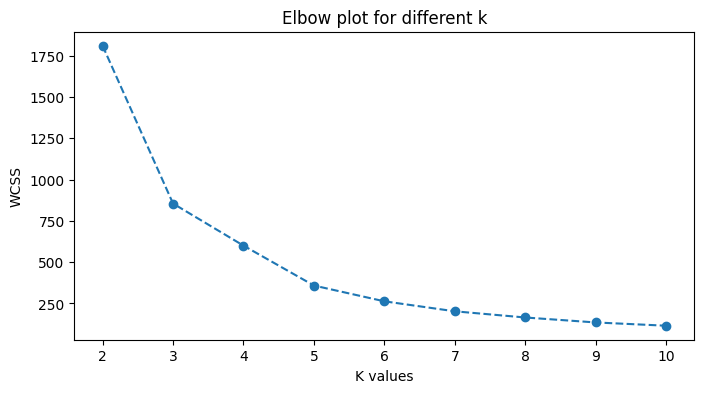

In [20]:
# Check the result with differenced series
p=2
h=50
features=window_cov(X_diff,h,d,30)
score=PCA_km(features)
k_means(score,lst_k)

In [21]:
k=3
kmeans=KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=SEED)
labels=kmeans.fit_predict(score)
features_groups=pd.DataFrame({
    'Window idx':np.arange(0,features.shape[0],1),
    'Cluster':labels+1})
for i,group in features_groups.groupby('Cluster'):
    print(f'Cluster {i} ({len(group)} intervals):{group.index}')

Cluster 1 (1401 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1401)
Cluster 2 (196 intervals):Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740,
       ...
       917, 918, 919, 920, 921, 922, 923, 924, 925, 926],
      dtype='int64', length=196)
Cluster 3 (63 intervals):Index([510, 511, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521, 522, 523,
       524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537,
       538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548, 549, 550, 551,
       552, 553, 554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565,
       566, 567, 568, 569, 570, 571, 572],
      dtype='int64')


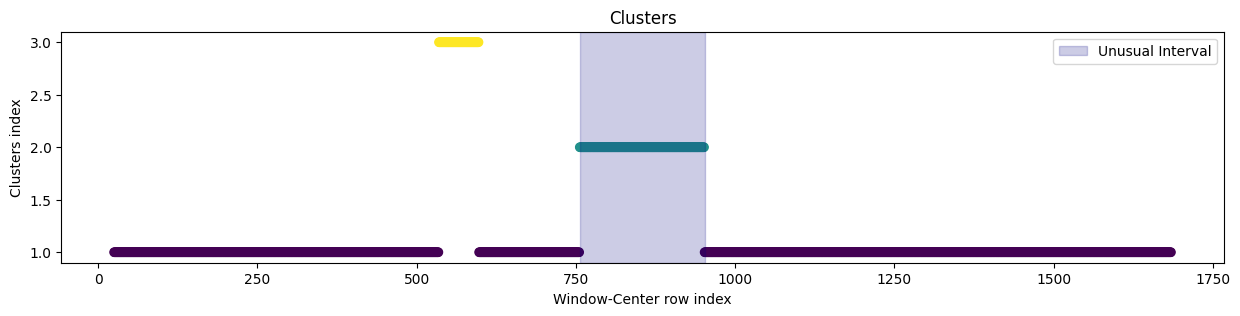

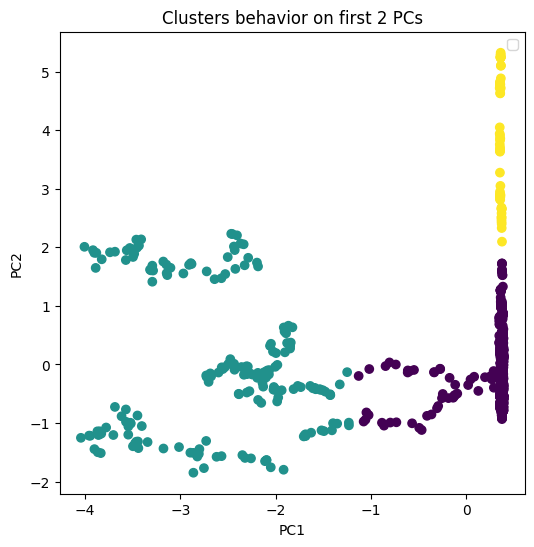

In [22]:
visualization(features_groups,h,d,731,928)

With the differenced data, the trace of window covariance matrices are displayed above, differencing smooth out the volatility in usual regim, but abnormal interval's sudden spike in changes is magnified through squaring, which is evident throgh the plot. PC1 therefore have huge explanatory power of variation, capturing the spike in absolute variance. The clustering however, yielding around the same result, thanks to the standardization of score.

# Task 4: Hierarchical clustering with temporal connectivity

Use a **window-level representation** from Task 3 to investigate time-series segmentation with **Ward hierarchical clustering and temporal connectivity constraints**.

1. Apply Ward clustering with a connectivity graph that links neighboring windows in chronological order. Select a reasonable number of segments.
2. Visualize the clustering labels over time and summarize the resulting contiguous segments and their boundaries.
3. Compare the segmentation and candidate change points with your K-means analysis in Task 3. Does it support a similar anomalous interval? Discuss important differences and limitations.

Remember that a segment boundary is a **candidate change point**, not automatically evidence of anomalous behavior.

(1660, 50, 29)


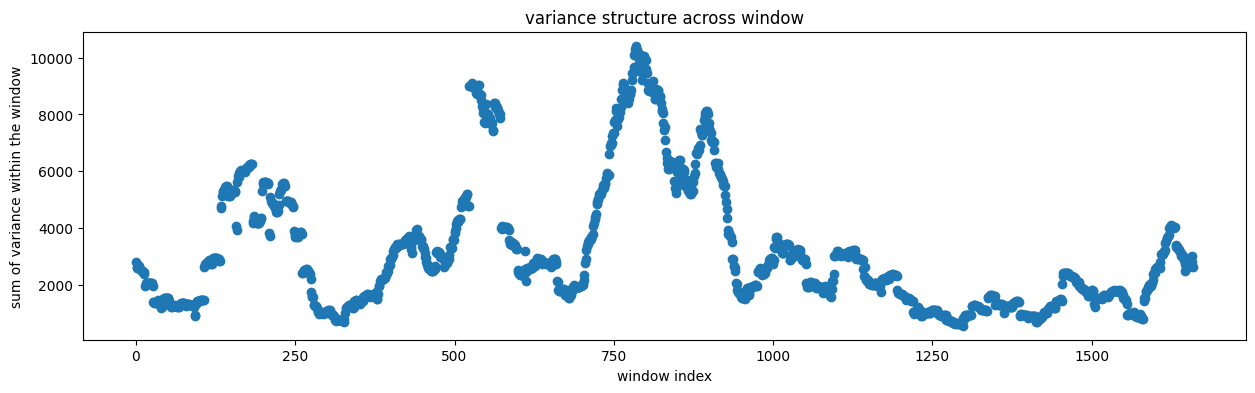

(1660, 435)
PC1 top features: [257 218 275 238 197]
PC2 top features: [170 172 180 177 235]
257 of PC1 top loadings is off-diagonal
218 of PC1 top loadings is off-diagonal
275 of PC1 top loadings is off-diagonal
238 of PC1 top loadings is off-diagonal
197 of PC1 top loadings is off-diagonal
170 of PC2 top loadings is off-diagonal
172 of PC2 top loadings is off-diagonal
180 of PC2 top loadings is off-diagonal
177 of PC2 top loadings is off-diagonal
235 of PC2 top loadings is off-diagonal
Explained variation at p=2 is 0.9032992434863317
Last 6 Ward merge heights (merges down to 6, 5, 4, 3, 2, 1 segments): [19.7 12.5 35.8 14.3 52.1 28.7]


,first window,last window,windows,first row covered,last row covered,center rows,mean PC1,mean PC2
0,0,742,743,0,791,25-767,0.50,-0.22
1,743,928,186,743,977,768-953,-0.59,2.60
2,929,1659,731,929,1708,954-1684,-0.36,-0.43


K = 2: boundaries at windows [929]
K = 3: boundaries at windows [743, 929]
K = 4: boundaries at windows [523, 743, 929]
K = 5: boundaries at windows [523, 573, 743, 929]
K = 6: boundaries at windows [275, 523, 573, 743, 929]


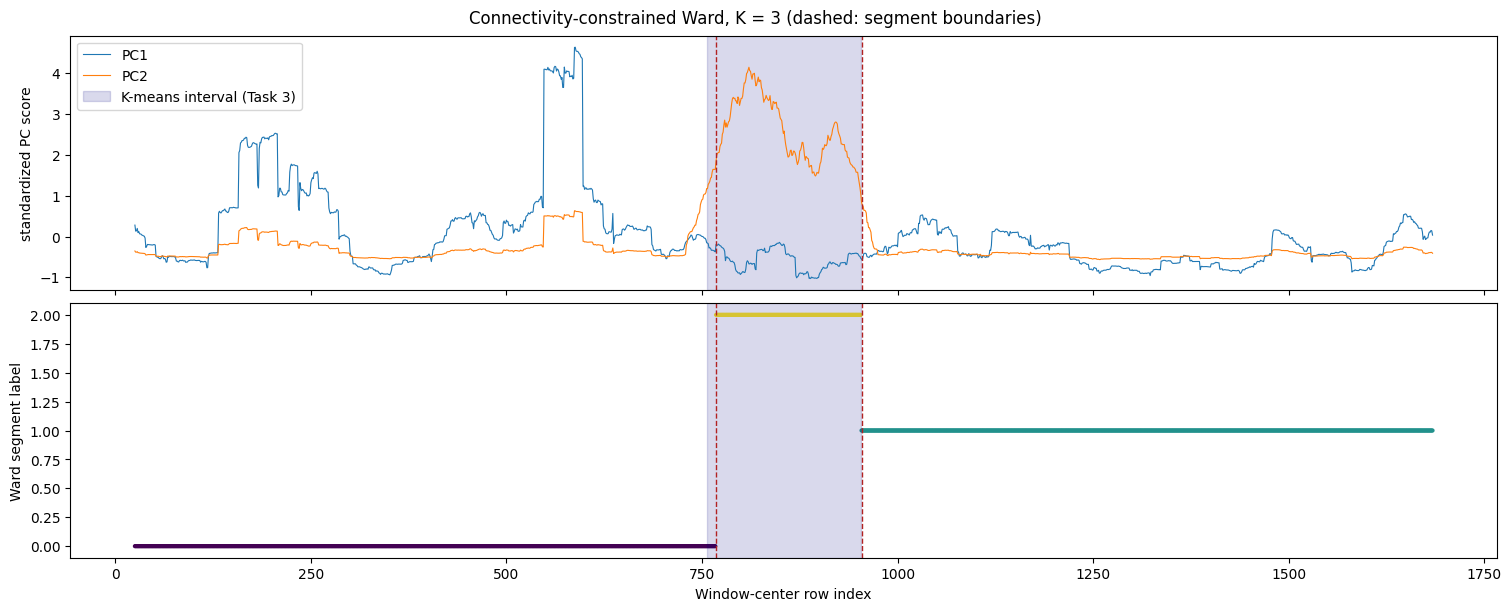

In [23]:
h, d = 50, 1
features = window_cov(df, h, d, 30)
score = PCA_km(features)
n_win = score.shape[0]

connectivity = sparse.diags([1, 1], [-1, 1], shape=(n_win, n_win))

def ward_segments(n_clusters):
    ward = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward', connectivity=connectivity,
                                   compute_distances=True)
    labels = ward.fit_predict(score)
    starts = np.r_[0, np.flatnonzero(np.diff(labels)) + 1]
    ends = np.r_[starts[1:] - 1, n_win - 1]
    return ward, labels, starts, ends

ward, labels, starts, ends = ward_segments(3)
print('Last 6 Ward merge heights (merges down to 6, 5, 4, 3, 2, 1 segments):', np.round(ward.distances_[-6:], 1))

segments = pd.DataFrame({
    'first window': starts, 'last window': ends, 'windows': ends - starts + 1,
    'first row covered': starts, 'last row covered': ends + h - 1,
    'center rows': [f'{s + h // 2}-{e + h // 2}' for s, e in zip(starts, ends)],
    'mean PC1': [score[s:e + 1, 0].mean() for s, e in zip(starts, ends)],
    'mean PC2': [score[s:e + 1, 1].mean() for s, e in zip(starts, ends)]})
display(segments.round(2))

for K in range(2, 7):
    print(f'K = {K}: boundaries at windows {ward_segments(K)[2][1:].tolist()}')

center = np.arange(n_win) + h // 2
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True, layout='constrained')
axes[0].plot(center, score[:, 0], lw=0.8, label='PC1')
axes[0].plot(center, score[:, 1], lw=0.8, label='PC2')
axes[0].set_ylabel('standardized PC score')
axes[1].scatter(center, labels, c=labels, s=4)
axes[1].set_ylabel('Ward segment label')
axes[1].set_xlabel('Window-center row index')
for ax in axes:
    ax.axvspan(731 + h // 2, 928 + h // 2, color='navy', alpha=0.15, label='K-means interval (Task 3)')
    for b in starts[1:]:
        ax.axvline(b + h // 2, color='firebrick', ls='--', lw=1)
axes[0].legend(loc='upper left')
fig.suptitle('Connectivity-constrained Ward, K = 3 (dashed: segment boundaries)')
plt.show()

### Discussion (Task 4)

**Same interval.** With $K=3$ contiguous segments, Ward isolates windows **743–928** (rows 743–977), which mostly matches the K-means interval from Task 3 (windows 731–928). The right end is identical (window 929 starts the next segment); the left end is 12 windows later.

**Why the left end differs.** PC2 rises gradually into the anomaly but drops sharply out of it. The windows on the rise mix normal and anomalous rows, so K-means (nearest centroid, window by window) and Ward (one cut minimizing the within-segment squared error) resolve them differently. We cannot pin down the start exactly; our estimate is between windows **731 and 743**.

**The extra boundaries are not anomalies.** At $K=4$ Ward adds a boundary at window 523 (a spike in PC1, the overall volatility level). It is most likely not an anomaly: K-means did not flag it, and Ward's cost of removing it (the 4→3 merge) is 14.3, against 52.1 for the boundary of the interval both methods flag (the 3→2 merge). A segment boundary is only a candidate change point.


# Task 5: Comparison and conclusion

Summarize the main findings from **DBSCAN, window covariance + PCA + K-means, and connectivity-constrained Ward**. Explain which approach is suited to isolated errors and which to an anomalous interval in the covariance structure.

Report your final six candidate recording-error observations and your best estimate of $[t_1,t_2]$, with brief evidence and limitations.

### Comparing the Different Clustering Methods & Suitabilities

The dataset, as mentioned before, has two types of irregularities: (1) **isolated errors** associated with the one-minute recordings and (2) contiguous interval covariance structure error. The three methods (DBSCAN, window covariance + PCA + K-means, and connectivity-constrained Ward) address these different issues because they use different features and treat time differently.

**DBSCAN, for isolated recording errors.** The half-hour intervals are represented by 28 local-deviation features: $$
r_{t,k}=x_{t,k}-\frac{x_{t,k-1}+x_{t,k+1}}{2},\qquad k=1,\ldots,28.
$$

For each half-hour, we measured how far every interior minute sits from the average of its two neighboring minutes. In a normal half-hour, prices drift gradually, so these gaps are small. A recording error looks different, where one reading jumps far away from the minutes before and after it, then returns to its earlier level. This is what these measurements are built to catch.

DBSCAN is a method that groups together observations that resemble many others and labels observations that resemble almost none as "noise". Similarity is measured using ordinary straight-line (Euclidean) distance. With the settings `eps = 45` (which defines how close two half-hours must be to count as neighbors), and `min_samples = 5` (which is how many neighbors a half-hour needs to be considered part of the crowd), DBSCAN found **one cluster of 1,703 half-hours and six noise observations**, meaning it found six half-hours that look unlike all the rest.

To check that this was not an accident of our settings, the analysis was repeated with nine nearby combinations of `eps` in `{40, 45, 50}` and `min_samples` in `{3, 5, 12}`.

DBSCAN suits isolated recording errors because a single large spike pushes that half-hour far from every other half-hour, leaving it alone. However, DBSCAN is not designed to locate a contiguous stretch of unusual behavior. If many consecutive half-hours are unusual in the same way, they resemble each other, so DBSCAN would treat them as one more crowd or cluster rather than as outliers or erroneous readings. Finding that kind of period requires methods that look at groups of consecutive half-hours together, which is what the window-based analysis in Tasks 3 and 4 does.

**Window covariance + PCA + K-means, for unusual covariance structure.**

A recording error is a single bad reading, but the second kind of irregularity is different: for a stretch of time, the prices behave differently as a group. To detect this, we stopped looking at half-hours one at a time and looked at rolling windows of 50 consecutive half-hours, sliding the window forward one half-hour at a time. Window 731, for example, covers half-hours 731 to 780. Each window is a table with 50 rows (the half-hours) and 29 columns (columns are filled with the price at that minute minus the price at the start of the half-hour; minute 0 is left out because it is always zero).

We start with half-hours 0-49, then move forward one half-hour at a time (1-50, then 2-51, and so on). The windows overlap heavily, and each one differs from the previous by a single half-hour. With 1,709 half-hours in total, this gives 1,709 - 50 + 1 = 1,660 windows.

Within each window, we measured how the 29 price-change readings (minutes 1 to 29) move together. The tool for this is the covariance matrix. It records how much each minute’s price change varies and how strongly each pair of minutes tends to rise and fall together. Because the matrix is symmetric, it contains 435 unique numbers, $$(29+(29^2-29)/2)$$ and we kept all of them as a “fingerprint” of each window. If the relationships between minutes change during some period, the fingerprints of windows in that period should look different from the rest.


Each fingerprint has 435 numbers, which is too many to inspect directly, so we simplified them in two steps. First, we standardized each of the 435 numbers across the 1,660 windows. Standardizing means rescaling a quantity so that it is measured relative to its own typical range (subtract its average, then divide by its spread). Without this, the entries that are naturally large, such as the diagonal entries showing how much a single minute varies, would dominate, and the subtler relationships between different minutes would be hard to see.

Then we applied **PCA** (principal component analysis), which condenses the 435 numbers into a few summary scores that capture the main ways the windows differ from one another. The first two scores (PC1 and PC2) capture about 90.33% of the variation, so little information was lost. Finally, we standardized these two scores in the same way, so that PC1, which naturally has the larger spread, does not overwhelm PC2 in the next step.

We used K-means clustering, which sorts windows into groups so that windows within a group look alike. We asked for `k = 2` groups, in effect "ordinary" versus "unusual." K-means placed 198 windows, numbered 731 to 928, in one group and the other 1,462 windows in the other.

The unusual windows have much larger PC2 values in absolute terms. PC2 therefore acts as a detector for a localized, sudden change in the covariance pattern that is concentrated in one specific period. To see what drives these scores, we looked at the covariance entries with the largest weights (loadings) in PC1 and PC2. All of them are off-diagonal entries, meaning they measure how strongly two different minutes move together rather than how much a single minute varies by itself. This suggests the unusual regime is mainly a change in the relationships between minutes, and not only a change in the volatility of particular minutes.

A window is named by the half-hour it starts at, but it covers 50 half-hours, so the window number isn’t the same as a position on the timeline. To say when something happened, we convert each window to a single half-hour near its middle. Window 731 covers half-hours 731 to 780. Its middle is about half-hour 756 (731 + 25). Window 928 covers half-hours 928 to 977, and its middle is about half-hour 953 (928 + 25). So the unusual windows, 731 to 928, correspond to center positions of about **756 to 953**. This is approximate.


**Connectivity-constrained Ward, for contiguous time segmentation.**

We used the same input as K-means: each of the 1,660 windows described by its two standardized PC scores. Ward clustering is hierarchical, meaning it builds groups from the bottom up. It begins with every window as its own group of one. At each step it merges the two groups whose combination increases the total internal spread the least, where spread means how far the members of a group sit from the group’s average. Groups that look similar are merged first, and the process repeats until only the desired number of groups, K, remains.

Without any restriction, Ward could merge two windows from opposite ends of the timeline if their fingerprints happened to look alike. To prevent this, we gave it a connectivity graph that links each window only to the window just before it and the window just after it. Two groups may merge only if they touch in time. Because of this rule, every group is always an unbroken run of consecutive windows, so the final result is a division of the timeline into segments with boundaries between them. Each boundary is a candidate point where the covariance pattern changes.

We set K = 3, which gives the smallest number of segments that can isolate a stretch in the middle of the timeline with ordinary behavior on both sides. With K = 2, the method can only draw a single boundary. Ward produced the following segments:

* windows 0 to 742
* windows **743 to 928**
* windows 929 to 1659

The middle segment is much shorter (186 windows, compared with 743 and 731) and has a very different location on PC2. Its average standardized PC2 score is **2.60**, compared with **−0.22** before it and **−0.43** after it. The segments on either side look alike on PC2, and the middle one stands apart.

Ward and K-means point to essentially the same unusual period. K-means selected windows **731 to 928**, and Ward’s middle segment is windows **743 to 928**. Converting windows to half-hours using each window’s center, as before, Ward’s period runs from about half-hour 768 to 953, compared with about 756 to 953 for K-means. The difference at the start arises because the windows near the edge of the unusual period contain a mix of normal and unusual half-hours, and the two methods treat those mixed windows differently. K-means assigns each window on its own to the closest group. Ward instead chooses where to cut the timeline so that the segments on either side are as internally uniform as possible. We therefore cannot pin down the start exactly, and we describe it as **lying between windows 731 and 743**.

A boundary tells us that the pattern changed at that point. It does not tell us that the change is abnormal. To show this, we increased K to 4, which adds a new boundary at window 523. K-means did not flag that point as unusual, so we treat it as an ordinary shift in the pattern rather than as an anomaly. The two main boundaries at windows 743 and 929 persist unchanged when we increase K to 4, 5 and 6. This repetition suggests they are the most prominent change points in the data. The one at 929 is the most stable, since it is the only boundary that appears even when K = 2. This is consistent with the end of the unusual period being sharper than its start.

**Overall comparison:** DBSCAN is preferable for finding **sparse, isolated measurement errors**, whereas rolling covariance features with **PCA + K-means** are better for finding an **extended change in relationships across minutes**, while **connectivity-constrained Ward** adds an explicit temporal segmentation to substantiate/further support the interval.

### Final Six-Candidate Recording-Error Observations and Best Estimate of [t1,t2]

Final six candidate recording errors:


,Half-hour,Minute,Previous,Recorded,Next,Local deviation,Absolute local deviation
0,90,1,0.00,60.38,1.70,59.530,59.530
1,351,2,-0.46,-56.96,4.47,-58.965,58.965
2,658,4,1.11,61.26,-0.63,61.020,61.020
3,1081,3,-2.15,-66.38,-5.65,-62.480,62.480
4,1334,5,0.06,61.23,0.48,60.960,60.960
5,1576,7,-4.22,-64.36,-3.97,-60.265,60.265



K-means anomalous windows contiguous: True

K-means anomalous windows: [731, 928]
K-means center interval: (755.5, 952.5)

Ward anomalous windows: [743, 928]
Ward center interval: (767.5, 952.5)

Start (t1) range across methods: [755.5, 767.5]
End (t2) range across methods:   [952.5, 952.5]

Best estimated anomalous interval: [762, 953]
Rows covered by anomalous windows: [731, 977]

Recording errors inside the estimated interval: []
Anomalous-group windows containing each error row: {90: 0, 351: 0, 658: 0, 1081: 0, 1334: 0, 1576: 0}


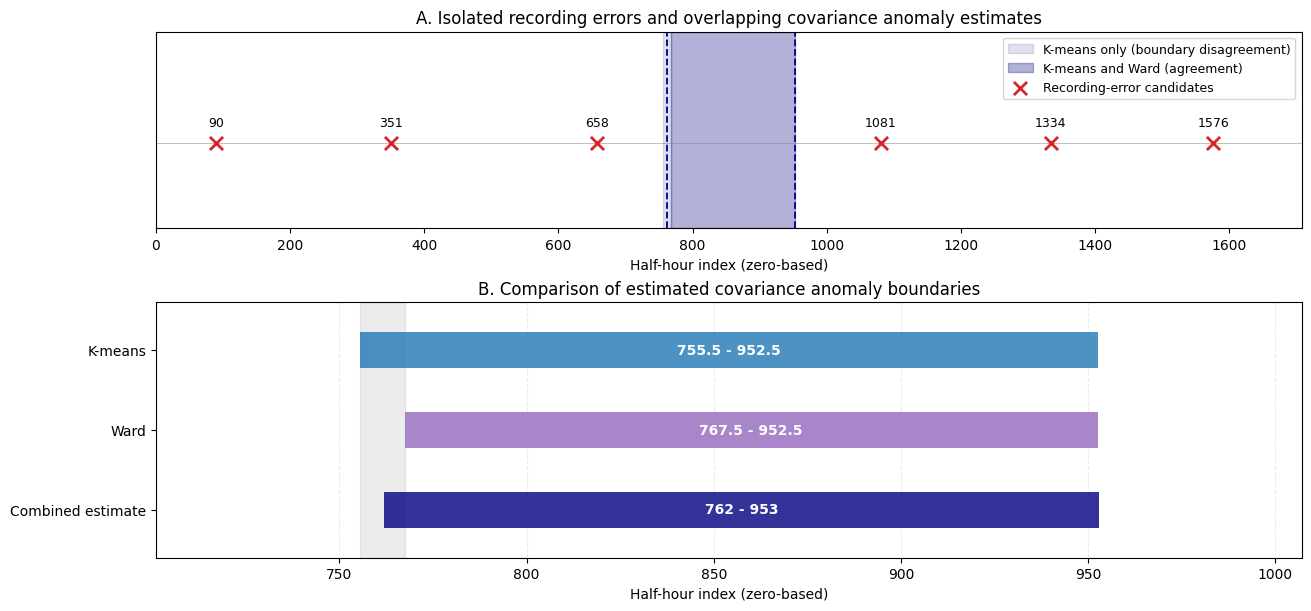

In [27]:
# uses error_summary, error_indices, time_idx, score, and ward_segments from Tasks 2-4.

# final six candidate recording errors
final_errors = error_summary.copy().sort_values("Half-hour").reset_index(drop=True)
final_errors["Absolute local deviation"] = final_errors["Local deviation"].abs()

print("Final six candidate recording errors:")
display(final_errors.round(3))

# K-means (k = 2) on the original-data PCA scores from Task 4
km_final = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=SEED)
km_labels = km_final.fit_predict(score)

# the smaller cluster is the candidate anomalous regime
anomaly_label = np.argmin(np.bincount(km_labels))
km_windows = np.flatnonzero(km_labels == anomaly_label)
km_start, km_end = int(km_windows.min()), int(km_windows.max())

print("\nK-means anomalous windows contiguous:",
      km_end - km_start + 1 == len(km_windows))

# Ward (K = 3): the segment with the largest |mean PC2|
_, _, w_starts, w_ends = ward_segments(3)
seg_pc2 = [abs(score[s:e + 1, 1].mean()) for s, e in zip(w_starts, w_ends)]
j = int(np.argmax(seg_pc2))
ward_start, ward_end = int(w_starts[j]), int(w_ends[j])

# convert windows to half-hours using exact window midpoints
# a window of h rows starting at row s covers rows s, ..., s + h - 1,
# so its midpoint is s + (h - 1) / 2.
h_final = 50
n_win = score.shape[0]
offset = (h_final - 1) / 2

km_centers = (km_start + offset, km_end + offset)
ward_centers = (ward_start + offset, ward_end + offset)

# average the two methods' center estimates and round half up
t1 = int(np.floor(np.mean([km_centers[0], ward_centers[0]]) + 0.5))
t2 = int(np.floor(np.mean([km_centers[1], ward_centers[1]]) + 0.5))

# range of start/end estimates across the two methods
# this is method disagreement, not a statistical confidence interval
t1_low, t1_high = sorted([km_centers[0], ward_centers[0]])
t2_low, t2_high = sorted([km_centers[1], ward_centers[1]])

print(f"\nK-means anomalous windows: [{km_start}, {km_end}]")
print(f"K-means center interval: {km_centers}")

print(f"\nWard anomalous windows: [{ward_start}, {ward_end}]")
print(f"Ward center interval: {ward_centers}")

print(f"\nStart (t1) range across methods: [{t1_low}, {t1_high}]")
print(f"End (t2) range across methods:   [{t2_low}, {t2_high}]")
print(f"\nBest estimated anomalous interval: [{t1}, {t2}]")

# outer bound: every row covered by any anomalous window (not a change-point estimate)
outer_lo = min(km_start, ward_start)
outer_hi = max(km_end, ward_end) + h_final - 1
print(f"Rows covered by anomalous windows: [{outer_lo}, {outer_hi}]")

# cross-checks between Task 2 and Tasks 3 & 4
errs = final_errors["Half-hour"].to_numpy(dtype=int)
inside = errs[(errs >= t1) & (errs <= t2)]
print("\nRecording errors inside the estimated interval:", inside.tolist())

flagged = np.zeros(n_win, dtype=bool)
flagged[km_windows] = True

# count anomalous K-means windows containing each recording-error row
touched = {
    int(r): int(flagged[max(0, r - h_final + 1):min(n_win, r + 1)].sum())
    for r in errs
}
print("Anomalous-group windows containing each error row:", touched)


# visualization
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(13, 6),
    gridspec_kw={"height_ratios": [1, 1.3]},
    constrained_layout=True
)

# panel 1: full timeline showing isolated errors and the anomalous interval
# lighter shading = identified by only one method
# darker shading = overlapping interval identified by both methods
ax1.axvspan(
    t1_low, t1_high, color="navy", alpha=0.12,
    label="K-means only (boundary disagreement)"
)
ax1.axvspan(
    t1_high, t2_low, color="navy", alpha=0.30,
    label="K-means and Ward (agreement)"
)

# show ending-boundary disagreement if the methods differ
if t2_low < t2_high:
    ax1.axvspan(t2_low, t2_high, color="navy", alpha=0.12)

# mark the combined estimated boundaries
for t in [t1, t2]:
    ax1.axvline(t, color="navy", linestyle="--", linewidth=1.3)

ax1.scatter(
    errs, np.zeros(len(errs)),
    marker="x", s=90, linewidths=2, color="tab:red",
    label="Recording-error candidates", zorder=3
)

# label each recording error by its half-hour index
for r in errs:
    ax1.annotate(
        str(r), (r, 0), xytext=(0, 12),
        textcoords="offset points", ha="center", fontsize=9
    )

ax1.axhline(0, color="gray", linewidth=0.7, alpha=0.5)
ax1.set_xlim(0, len(time_idx) - 1)
ax1.set_ylim(-0.5, 0.65)
ax1.set_yticks([])
ax1.set_xlabel("Half-hour index (zero-based)")
ax1.set_title("A. Isolated recording errors and overlapping covariance anomaly estimates")
ax1.legend(loc="upper right", fontsize=9)


# panel 2: zoomed-in comparison of the two clustering methods
# each bar shows the midpoints of windows assigned to the anomalous regime
methods = [
    ("K-means", km_centers, "tab:blue", 2),
    ("Ward", ward_centers, "tab:purple", 1),
    ("Combined estimate", (t1, t2), "navy", 0)
]

# lighter shading shows disagreement in the estimated starting boundary
# this is not a formal confidence interval
ax2.axvspan(
    t1_low, t1_high,
    color="gray", alpha=0.15,
    label="Starting-boundary disagreement"
)

for name, (start, end), color, y in methods:
    ax2.barh(
        y, end - start, left=start,
        height=0.45, color=color, alpha=0.80
    )
    ax2.text(
        (start + end) / 2, y,
        f"{start:g} - {end:g}",
        ha="center", va="center",
        color="white", fontsize=10, fontweight="bold"
    )

ax2.set_yticks([2, 1, 0])
ax2.set_yticklabels(["K-means", "Ward", "Combined estimate"])
ax2.set_xlim(outer_lo - 30, outer_hi + 30)
ax2.set_ylim(-0.6, 2.6)
ax2.set_xlabel("Half-hour index (zero-based)")
ax2.set_title("B. Comparison of estimated covariance anomaly boundaries")
ax2.grid(axis="x", linestyle="--", alpha=0.25)
ax2.set_axisbelow(True)

plt.show()



## Final Six-Candidate Recording-Error Observations and Best Estimate of $[t_1,t_2]$

### 1. Final Six Recording-Error Candidates

Running DBSCAN with `eps = 45` and `min_samples = 5` gave one cluster of 1,703 observations and six noise points. These six are our final candidate recording errors:

| Half-hour $t$ | Minute $k$ | Recorded value (price units) | Local deviation (price units) |
|---|---|---|---|
| 90 | 1 | 60.38 | +59.530 |
| 351 | 2 | -56.96 | -58.965 |
| 658 | 4 | 61.26 | +61.020 |
| 1081 | 3 | -66.38 | -62.480 |
| 1334 | 5 | 61.23 | +60.960 |
| 1576 | 7 | -64.36 | -60.265 |

Each one is a large single-minute spike that reverses right away, with absolute local deviations between 58.965 and 62.480 price units. The fourth-neighbor distance plot has a clear gap between 37.919 and 59.300, and these six sit on the far side of it. The same six points were flagged in all nine parameter combinations (`eps = 40, 45, 50` and `min_samples = 3, 5, 12`), so the result is stable, which supports treating them as recording-error candidates.

### 2. Best Estimate of the Anomalous Interval

Our final estimate is:

$$
\boxed{[\hat{t}_1,\hat{t}_2]=[762,953]}
$$

We used rolling covariance windows of 50 half-hours, then PCA and K-means with $k=2$. This flagged windows **731–928** as anomalous, which corresponds to roughly **half-hours 756–953** when each window is mapped to its center row.

Ward clustering with temporal connectivity and $K=3$ (a before, anomalous, and after segment) gives a similar picture, though it uses the same features and PCA scores, so it is a check on the clustering method and not fully independent evidence. Its middle segment covers windows **743–928**, or roughly **half-hours 768–953**. That segment's mean standardized PC2 score (2.60) is much higher than the segments before it (-0.22) and after it (-0.43), which points to a real shift in covariance structure.

The two methods put the start somewhere between **756 and 768** and the end near **953**. We take $t_1=762$, the midpoint of the two start estimates. This is a practical choice, not a statistically derived one, so our best point estimate is **$[762,953]$**.

These conversions assume column 0 matches the row position. Mapping a window to its center row introduces only a ~0.5-row offset (24.5 vs. 25), which is negligible next to the boundary uncertainty from window blur described below.

### 3. Limitations and Uncertainty

The six recording errors are candidates, not confirmed errors, since a genuine extreme price move could look the same. The DBSCAN results also depend on the parameters: `eps = 35` flags an extra observation (1644), and `eps = 55` absorbs two of the candidates (90 and 351). So the stability only holds for `eps = 40–50`, and we picked `eps` partly because we knew there should be six errors.

For the interval, the overlapping 50-half-hour windows blur the change points, since windows near the boundaries mix normal and unusual rows. Both methods put the end near 953, but K-means sometimes moves window 928 into the usual cluster for other values of $k$, so the end boundary is not certain either. The start estimates range from 756 to 768. This spread reflects sensitivity to the method, not a formal confidence interval. Windows touching the anomaly span half-hours 731–977, but that is an outer bound and not our estimate of the interval itself.

Finally, none of the six candidate errors fall inside our estimated interval or the anomalous K-means windows. That fits the idea that isolated recording errors are separate from the longer covariance anomaly, but Task 2 never assumed this, and it does not independently confirm the interval.